In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Task1
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score
import pandas as pd
import string

df = pd.read_csv('/content/drive/MyDrive/CSE440/IMDB Dataset.csv')
df = df.rename(columns={'review': 'text', 'sentiment': 'label'})

def preprocess(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    return text

df['processed'] = df['text'].apply(preprocess)

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['processed'])
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
f1 = f1_score(y_test, y_pred, average='weighted')
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.7546


In [ ]:
#Task 2
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

embeddings = {}
with open('/content/drive/MyDrive/CSE440/glove.6B.200d.txt', 'r', encoding='utf-8') as file:
    for line in file:
        values = line.strip().split()
        word = values[0]
        vector = values[1:]
        if len(vector) == 200:
            embeddings[word] = np.asarray(vector, dtype='float32')

def analogy(a, b, c, embeddings):
    if a not in embeddings or b not in embeddings or c not in embeddings:
        raise ValueError("One of the words is not in the vocabulary.")
    vec = embeddings[a] - embeddings[b] + embeddings[c]
    similarities = {}
    for word, vector in embeddings.items():
        if word not in [a, b, c]:
            similarities[word] = cosine_similarity([vec], [vector])[0][0]
    return max(similarities.items(), key=lambda x: x[1])

result = analogy('queen', 'female', 'male', embeddings)
print(f"{result[0]} (Similarity: {result[1]:.4f})")


king (Similarity: 0.6505)


In [ ]:
!pip install --upgrade numpy
!pip install --upgrade --force-reinstall scikit-learn gensim
!pip install --upgrade numpy scipy
!pip install --force-reinstall gensim

  Using cached numpy-2.2.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
Using cached numpy-2.2.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.4 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.2.4 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.2.4 which is incompatible.
tensorflow 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 2.2.4 which is incompatible.
  Using cached scikit_learn-1.6.1-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (18 kB)
  Using cached gensim-4.3.3-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (8.1 kB)
  Using cached numpy-2.2.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
  Using cached scipy-1.15.2-cp311-c

  Using cached numpy-2.2.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
  Using cached scipy-1.15.2-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-2.2.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.4 MB)
Using cached scipy-1.15.2-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (37.6 MB)
ERROR: Operation cancelled by user
^C
^C


[nltk_data] Downloading package reuters to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Similarity between 'company' and 'firm': 0.4356
Word not in vocabulary: "Key 'woman' not present in vocabulary"


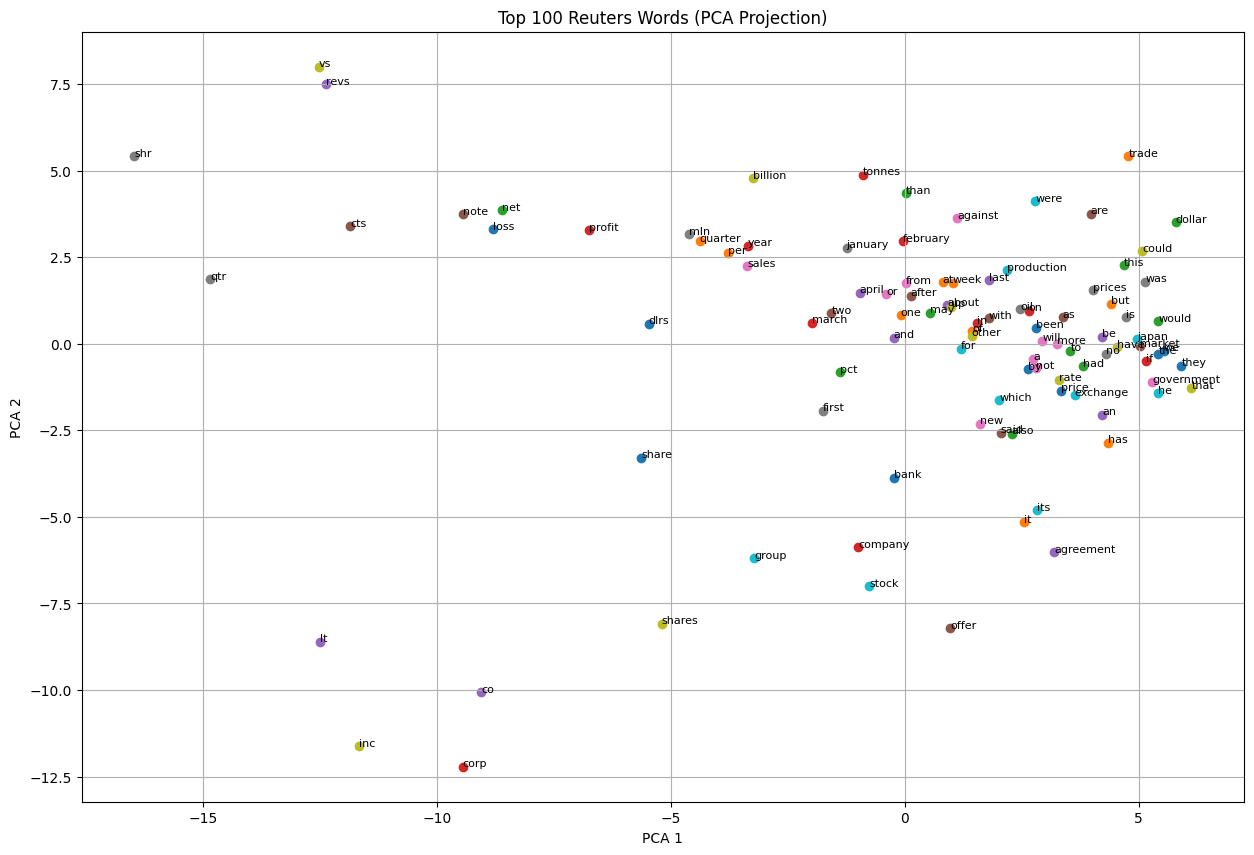

In [ ]:
#Task 3
import nltk
from nltk.corpus import reuters
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

nltk.download('reuters')
nltk.download('punkt')
nltk.download('punkt_tab', force=True)

sentences = []
for file_id in reuters.fileids():
    raw_text = reuters.raw(file_id)
    tokens = word_tokenize(raw_text.lower())
    words = [word for word in tokens if word.isalpha()]
    if words:
        sentences.append(words)

model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=4)

try:
    sim = model.wv.similarity("company", "firm")
    print(f"Similarity between 'company' and 'firm': {sim:.4f}")
except KeyError as e:
    print(f"Word not in vocabulary: {e}")

try:
    analogy = model.wv.most_similar(positive=["Queen", "Male"], negative=["Female"], topn=1)
    print(f"Analogy result for 'Queen' - 'Female' + 'Male': {analogy}")
except KeyError as e:
    print(f"Word not in vocabulary: {e}")

all_words = [word for sent in sentences for word in sent]
word_freq = Counter(all_words)
top_words = [word for word, _ in word_freq.most_common(100) if word in model.wv]

vectors = np.array([model.wv[word] for word in top_words])
pca = PCA(n_components=2)
vectors_2d = pca.fit_transform(vectors)

plt.figure(figsize=(15, 10))
for i, word in enumerate(top_words):
    plt.scatter(vectors_2d[i, 0], vectors_2d[i, 1])
    plt.annotate(word, xy=(vectors_2d[i, 0], vectors_2d[i, 1]), fontsize=8)
plt.title("Top 100 Reuters Words (PCA Projection)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.grid(True)
plt.show()